In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pdb
from IPython.display import display
import os
import seaborn as sns
import statsmodels.formula.api as sm
from numpy.polynomial.polynomial import polyfit
from sklearn.model_selection import train_test_split
import sklearn
from math import sqrt
import glob

In [99]:
import ee
import geemap
service_account = ' boba-account@boba-430314.iam.gserviceaccount.com '
credentials = ee.ServiceAccountCredentials(service_account,'C:/Users/arj26323/OneDrive - University of Georgia/Documents/GEE AUTH/boba-430314-a19be859bfca.json')

ee.Initialize(credentials)

print(geemap.__version__)

0.34.1


In [100]:
##LOAD PREFORMATTED CSV - BE CAREFUL

df = pd.read_csv('C:/Users/arj26323/Documents/Data/Biomass datasets/Pennings/Final_df_interpolated/LOGO_df_interpolated.csv')

df['Sampling_year'] = df['Year']

'''
nested cross validation

why overfitting
learn rfs
designing features/feature engineering (rather than just standard scaler)
bucketize features - try with linear regression or non tree model: sklearn.preprocessing.KBinsDiscretizer
data augmentation (complicated)
turn into classification? bucketized output (biomass bucketed into 100 g/m2 or so)
'''

'\nnested cross validation\n\nwhy overfitting\nlearn rfs\ndesigning features/feature engineering (rather than just standard scaler)\nbucketize features - try with linear regression or non tree model: sklearn.preprocessing.KBinsDiscretizer\ndata augmentation (complicated)\nturn into classification? bucketized output (biomass bucketed into 100 g/m2 or so)\n'

In [101]:
##FILTERS

df0 = df.copy()
df0['Sampling_year'] = df0['Sampling_year'].astype(str) #Needed after discharge merge

##Including species
allplots_fc = pd.read_csv('C:/Users/arj26323/Documents/Data/Biomass datasets/Sapelo/GA_allplots_NEW.csv')
sp_df = allplots_fc[['Plant_Biomass', 'Longitude', 'Latitude', 'Species_Code', 'Year', 'Zone']]
dfx = pd.merge(df0, sp_df, on = ['Plant_Biomass', 'Latitude', 'Longitude', 'Year'], how = 'left')

df0 = dfx ##Careful with this circular object naming

df0['Plant_Biomass'] = np.where(df0['Year'] == 2002, df0['Plant_Biomass'] / 2, df0['Plant_Biomass'])



##ADDING IN PLOT AND ZONE DATA FOR TRAIN/VAL LOOp
df0["Plot"] = df0.groupby(["Site", "Zone", "Year"]).cumcount() + 1



'''REMOVE SITE if running all xargs'''


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
import numpy as np

seed = 3

yargs=df0['Plant_Biomass'] 


##best features


xargs = df0[['evi_max_05_10',
             'slope',
             'elevation',
             'Percent_flooding',
             'srad_peak',
             'dayl_Max',
             'nd_swir2_nir_mean_05_10',
             'ndvi_mean_08_10',
             'nd_r_g_max_05_10',
             'spei14d'
            ]]



# predictors / target
X = xargs
y = yargs
groups = df0['Site']

year_index = df0['Year']


features = xargs.columns


In [102]:
# 1. Combine your predictors, target, and metadata into one clean modeling dataframe
# (Assuming xargs and yargs share the exact same clean index)
model_df = xargs.copy()
model_df['Plant_Biomass'] = yargs
model_df['Site'] = df0['Site'].loc[xargs.index]  # Ensure matching indices
model_df['Year'] = df0['Year'].loc[xargs.index]
model_df['Zone'] = df0['Zone'].loc[xargs.index]

# 2. Create your recycling Plot column on this aligned dataframe
model_df['Plot'] = model_df.groupby(['Site', 'Zone', 'Year']).cumcount() + 1

# 3. Define your variables from model_df so their indices are 100% guaranteed to match
X = model_df.drop(columns=['Plant_Biomass', 'Site', 'Year', 'Zone', 'Plot'])
y = model_df['Plant_Biomass']
groups = model_df['Site']
year_index = model_df['Year']

In [103]:
from sklearn.model_selection import GroupKFold, cross_validate
from scipy.stats import pearsonr

gkf = GroupKFold(n_splits=10)

'''kf_groups = groups.loc[~test_mask]
'''

kf_groups = groups

# kf_groups= kf_groups.sample(frac = 1) ##borscht

'''for fold, (train_idx, val_idx) in enumerate(gkf.split(X_remaining, y_remaining, kf_groups)):

    train_x = X_remaining.iloc[train_idx]
    train_y = y_remaining.iloc[train_idx]
    
    val_x = X_remaining.iloc[val_idx]
    val_y = y_remaining.iloc[val_idx]
    
'''

train_rmses = []
val_rmses = []
pearsons = []
pearsons_training = []
importances_list = []
plot_data_list = []
train_counts = []
val_counts = []

exclude_sites = [7, 8] ##Remove these sites from analysis

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, kf_groups)):
    
    train_groups = kf_groups.iloc[train_idx]
    val_groups = kf_groups.iloc[val_idx]
    
    val_groups_set = set(val_groups.unique())
    
    # Check if any excluded sites are in the current validation fold
    if any(site in val_groups_set for site in exclude_sites):
        print(f"\tSkipping Fold {fold} (contains excluded sites: {exclude_sites})")
        continue # Skip this iteration entirely
    
    train_x = X.iloc[train_idx]
    train_y = y.iloc[train_idx]
    
    val_x = X.iloc[val_idx]
    val_y = y.iloc[val_idx]

    print(f"\nFold {fold}:")
    print(f"\tTraining groups: {((train_groups)).unique()}")
    print(f"\tValidation groups: {((val_groups)).unique()}")
    
    train_sites = set(kf_groups.iloc[train_idx])
    val_sites = set(kf_groups.iloc[val_idx])
    
    print("Overlap:", train_sites.intersection(val_sites))
    
    estimator = RandomForestRegressor( ##TRY: n_est 500, minsplit 10, minleaf 25 or 30, max depth 7 or  10  (mayyybe 500 5 10 5)
        n_estimators=500,
        min_samples_split=10,
        min_samples_leaf=25,
        max_depth=7,
        random_state=seed
    )
#     estimator = sklearn.ensemble.GradientBoostingRegressor()
#     estimator = sklearn.neighbors.KNeighborsRegressor()
#     estimator = sklearn.linear_model.LinearRegression()
#     estimator = sklearn.svm.SVR()

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('estimator', estimator)
    ])

    pipe.fit(train_x, train_y)
    
    train_pred_y = pipe.predict(train_x)
    val_pred_y = pipe.predict(val_x)
    
    train_rmse = np.sqrt(metrics.mean_squared_error(train_pred_y, train_y))
    val_rmse = np.sqrt(metrics.mean_squared_error(val_pred_y, val_y))
    
    r2 = r2_score(val_y, val_pred_y)
    r2_training = r2_score(train_y, train_pred_y)

    r_pears, p_value = pearsonr(val_y, val_pred_y)
    r_pears_training, p_value_training = pearsonr(train_y, train_pred_y)

    importances = pipe.named_steps['estimator'].feature_importances_
    
    t_count = len(train_pred_y)
    v_count = len(val_pred_y)
    
# 2. Store training results
    train_df = pd.DataFrame(
        {
            'Observed': train_y,
            'Predicted': train_pred_y,
            'Site': groups.iloc[train_idx],
            'Plot': model_df['Plot'].iloc[
                train_idx
            ],  # <--- Now perfectly aligned!
            'Zone': model_df['Zone'].iloc[
                train_idx
            ],  # <--- Now perfectly aligned!
            'Year': year_index.iloc[train_idx],
            'Species': df0['Species_Code'].iloc[train_idx],  # If needed
            'Type': 'Training',
            'Fold': fold,
        }
    )

    # 3. Store validation results
    val_df = pd.DataFrame(
        {
            'Observed': val_y,
            'Predicted': val_pred_y,
            'Site': groups.iloc[val_idx],
            'Plot': model_df['Plot'].iloc[val_idx],  # <--- Now perfectly aligned!
            'Zone': model_df['Zone'].iloc[val_idx],  # <--- Now perfectly aligned!
            'Year': year_index.iloc[val_idx],
            'Species': df0['Species_Code'].iloc[val_idx],  # If needed
            'Type': 'Testing',
            'Fold': fold,
        }
    )
    
    plot_data_list.extend([train_df, val_df]) ###
    
    print('\ttrain rmse:\t{:.2f}'.format(train_rmse))
    print('\tval rmse:\t{:.2f}'.format(val_rmse))
    print('\tr2:\t{:.2f}'.format(r2))
    print(f"\tPearson r: {r_pears:.2f}, p-value: {p_value:.3f}")
    print(f"\tPearson TRAIN r: {r_pears_training:.2f}, p-value TRAIN: {p_value_training:.3f}")

    
    train_rmses.append(train_rmse)
    val_rmses.append(val_rmse)
    pearsons.append(r_pears)
    pearsons_training.append(r_pears_training)
    importances_list.append(importances)
    train_counts.append(t_count)
    val_counts.append(v_count)

    

print('***')
print('mean train rmse:\t{:.2f}'.format(np.mean(train_rmses)))
print('mean val rmse:\t{:.2f}'.format(np.mean(val_rmses)))
print('mean pearson r:\t{:.2f}'.format(np.mean(pearsons)))
print('mean pearson r TRAIN:\t{:.2f}'.format(np.mean(pearsons_training)))

mean_importances = np.mean(importances_list, axis=0)
feature_names = X.columns
importance_df = pd.DataFrame({'feature': feature_names, 'importance': mean_importances})
print(importance_df.sort_values(by='importance', ascending=False))

print('count of samples TRAIN:\t{:.2f}'.format(np.mean(train_counts)))
print('count of samples VAL:\t{:.2f}'.format(np.mean(val_counts)))

all_results = pd.concat(plot_data_list).reset_index(drop=True)

print('\n***')
print('all_results check:')

# 1. Filter to only look at Validation ('Testing') results
val_results = all_results[all_results['Type'] == 'Testing']

# 2. Define a quick function to calculate RMSE for a given group
def calc_group_rmse(group):
    mse = metrics.mean_squared_error(group['Observed'], group['Predicted'])
    return np.sqrt(mse)

# 3. Group by Species and apply the calculation
species_rmse_df = val_results.groupby('Species').apply(calc_group_rmse).reset_index(name='RMSE')

print("\n--- Cross-Validated RMSE by Species ---")
print(species_rmse_df.sort_values(by='RMSE'))



Fold 0:
	Training groups: [8 7 9 6 5 4 3 2 1]
	Validation groups: [10]
Overlap: set()
	train rmse:	398.62
	val rmse:	414.55
	r2:	-0.63
	Pearson r: 0.27, p-value: 0.000
	Pearson TRAIN r: 0.79, p-value TRAIN: 0.000

Fold 1:
	Training groups: [ 8  7  9  6  5  4 10  3  1]
	Validation groups: [2]
Overlap: set()
	train rmse:	377.48
	val rmse:	532.86
	r2:	0.08
	Pearson r: 0.39, p-value: 0.000
	Pearson TRAIN r: 0.80, p-value TRAIN: 0.000

Fold 2:
	Training groups: [ 8  7  9  5  4 10  3  2  1]
	Validation groups: [6]
Overlap: set()
	train rmse:	386.96
	val rmse:	430.49
	r2:	0.41
	Pearson r: 0.67, p-value: 0.000
	Pearson TRAIN r: 0.78, p-value TRAIN: 0.000
	Skipping Fold 3 (contains excluded sites: [7, 8])

Fold 4:
	Training groups: [ 8  7  9  6  5  4 10  2  1]
	Validation groups: [3]
Overlap: set()
	train rmse:	393.44
	val rmse:	402.49
	r2:	-0.30
	Pearson r: 0.44, p-value: 0.000
	Pearson TRAIN r: 0.79, p-value TRAIN: 0.000

Fold 5:
	Training groups: [ 8  7  9  6  5 10  3  2  1]
	Validation gro

In [104]:
# df_spp = val_results.groupby(['Site','Species']).apply(calc_group_rmse).reset_index(name='RMSE')

# df_spp

# 436/df0['Plant_Biomass'].max()

##POOLED R2 SCORES:
print("POOLED: ")

val_all = all_results[all_results['Type'] == 'Testing'] ##Later, this changes to 'Cat' column and 'Validation' instead of test

v_obs = val_all['Observed']
v_pred = val_all['Predicted']

global_rmse = np.sqrt(mean_squared_error(v_obs, v_pred))
global_r2 = r2_score(v_obs, v_pred)
global_pearson, _ = pearsonr(v_obs, v_pred)

print("="*40)
print("GLOBAL (POOLED) VALIDATION METRICS")
print("="*40)
print(f"Pooled RMSE:\t\t{global_rmse:.2f}")
print(f"Pooled Standard R^2:\t{global_r2:.2f}")
print(f"Pooled Pearson r^2:\t{global_pearson**2:.2f}")

POOLED: 
GLOBAL (POOLED) VALIDATION METRICS
Pooled RMSE:		445.81
Pooled Standard R^2:	0.12
Pooled Pearson r^2:	0.16


C:\Users\arj26323\AppData\Local\Temp\ipykernel_18136\1091054557.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_results['resids'] = x_results['Observed'] - x_results['Predicted']


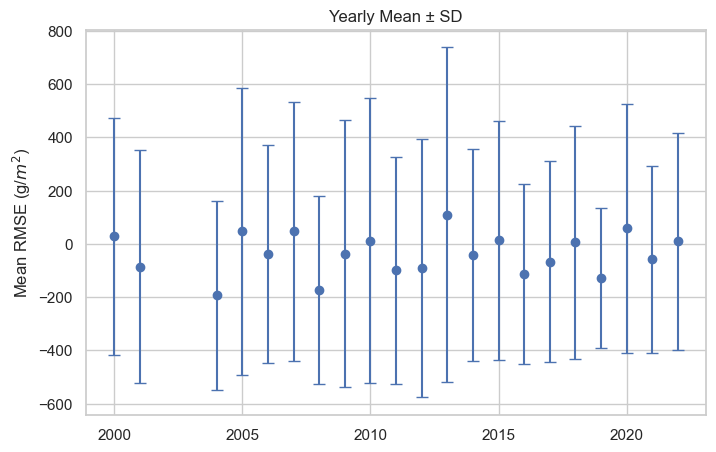

In [105]:
##Summary performance by site and year


# train_rmses
# val_rmses
# pearsons
# train_counts
# val_counts
val_results

target_sites = [1, 2, 3, 4, 5, 6, 9, 10] ##Spartina and Juncus
anti_years = [2002]
xy_results = val_results[val_results['Site'].isin(target_sites)]
x_results = xy_results[~xy_results['Year'].isin(anti_years)]
x_results['resids'] = x_results['Observed'] - x_results['Predicted']

def calculate_rmse(group):
    return np.sqrt(metrics.mean_squared_error(group['Observed'], group['Predicted']))

# Group by Year and apply the calculation
yearly_rmse = x_results.groupby('Year').apply(calculate_rmse).reset_index()
# yearly_resid = pd.DataFrame(x_results.groupby(x_results['Year'])['resids'].mean().reset_index())

yearly_rmse
# yearly_resid
##Issues with 2002 - combining RMSE for some reason

# # Group by Year and apply the calculation
# site_rmse = x_results.groupby('Site').apply(calculate_rmse).reset_index()
# site_rmse


##Exporting
out_dir = os.path.expanduser('~/Downloads')
out_csv = os.path.join(out_dir, 'test_resids.csv')
#x_results.to_csv(out_csv)


# Calculate yearly statistics
yearly = (
    x_results.groupby('Year')['resids']
      .agg(['mean', 'std', 'count'])
      .reset_index()
)

# Plot
plt.figure(figsize=(8,5))
plt.errorbar(
    yearly['Year'],
    yearly['mean'],
    yerr=yearly['std'],
    fmt='o',
    capsize=4
)

plt.xlabel('')
plt.ylabel('Mean RMSE (g/$m^2$)')
plt.title('Yearly Mean ± SD')

##Save at high res
import os
output_dir = r'F:\Loose figures'
file_name = 'rmse_throughtime_errorbars.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)

plt.show()

# yearly_resid ##No patterns in the residuals, nor in the RMSE. Looks good!

In [110]:
##2024 validation (peak and year gridmet, testing a theory that the spei14d is actually PEAK instead of YEAR)
val_year = pd.read_csv('C:/Users/arj26323/Documents/All extract/2024_Validation/val_year.csv')
val_peak = pd.read_csv('C:/Users/arj26323/Documents/All extract/2024_Validation/val_peak.csv')

'''##Aggregating by zone
val_peak['Site'] = val_peak['Site_x']
val_peak['dayl_Max'] = val_peak['dayl_max']

dfx = pd.merge(val_peak, sp_df, on = ['Latitude', 'Longitude'], how = 'left')

dfx['Species_Code'] = dfx['Species_Code_x']
dfx['Plant_Biomass'] = dfx['Plant_Biomass_x']


val_grouped = dfx.groupby(['Zone', 'Site'], as_index = False).aggregate(
    {
        'Plant_Biomass':[np.mean],'Longitude':[np.mean], 'Latitude':[np.mean], 'evi_max_05_10':[np.mean], 'slope':[np.mean],
        'elevation':[np.mean], 'Percent_flooding':[np.mean], 'srad_peak':[np.mean], 'dayl_Max':[np.mean], 
        'nd_swir2_nir_mean_05_10':[np.mean], 'ndvi_mean_08_10':[np.mean], 'nd_r_g_max_05_10':[np.mean], 'spei14d':[np.mean],
        'Species_Code':'first'
    }
) 
val_grouped.columns = [
    'Zone','Site','Plant_Biomass', 'Longitude', 'Latitude', 'evi_max_05_10', 'slope', 'elevation', 'Percent_flooding',
    'srad_peak', 'dayl_Max', 'nd_swir2_nir_mean_05_10', 'ndvi_mean_08_10', 'nd_r_g_max_05_10', 'spei14d',
    'Species_Code'
]

val_peak = val_grouped ##Circular again'''

# val_year = val_year[val_year['Site_x'] != 8]
# val_peak = val_peak[val_peak['Site_x'] != 8]  ##Removing Sites 7 and 8, and getting rid of outliers (3000+ g/m2)

# val_year = val_year[val_year['Site_x'] != 7]
# val_peak = val_peak[val_peak['Site_x'] != 7]

# val_year = val_year[val_year['Plant_Biomass'] < 3000]
# val_peak = val_peak[val_peak['Plant_Biomass'] < 3000]

##Renaming dayl_Max
val_year['dayl_Max'] = val_year['dayl_max']
val_peak['dayl_Max'] = val_peak['dayl_max']

year_spei14d = val_year['spei14d']
peak_spei14d = val_peak['spei14d']

year_val = val_year['Plant_Biomass']
peak_val = val_peak['Plant_Biomass']

year_xargs = val_year[['evi_max_05_10',
             'slope',
             'elevation',
             'Percent_flooding',
             'srad_peak',
             'dayl_Max',
             'nd_swir2_nir_mean_05_10',
             'ndvi_mean_08_10',
             'nd_r_g_max_05_10',
             'spei14d']]

peak_xargs = val_peak[['evi_max_05_10',
             'slope',
             'elevation',
             'Percent_flooding',
             'srad_peak',
             'dayl_Max',
             'nd_swir2_nir_mean_05_10',
             'ndvi_mean_08_10',
             'nd_r_g_max_05_10',
             'spei14d']]

pred_valyear = pipe.predict(year_xargs)
pred_valpeak = pipe.predict(peak_xargs)

# plt.figure(figsize=(5, 5))
# plt.scatter(year_val, pred_valyear, alpha=0.4)
# plt.plot(
#     [year_val.min(), year_val.max()],
#     [year_val.min(), year_val.max()],
#     linestyle='--'
# )

# plt.xlabel('Observed Plant Biomass (g/$m^2$)')
# plt.ylabel('Predicted Plant Biomass (g/$m^2$)')
# plt.title('Performance on held-out 2024 data')

# plt.tight_layout()
# plt.show()

# print(r2_score(year_val, pred_valyear))
# print(pearsonr(year_val, pred_valyear))
# print(np.sqrt(metrics.mean_squared_error(year_val, pred_valyear)))

# g = sns.FacetGrid(val_peak, col = 'Species_Code')
# g.map_dataframe(sns.histplot, x = 'Plant_Biomass')

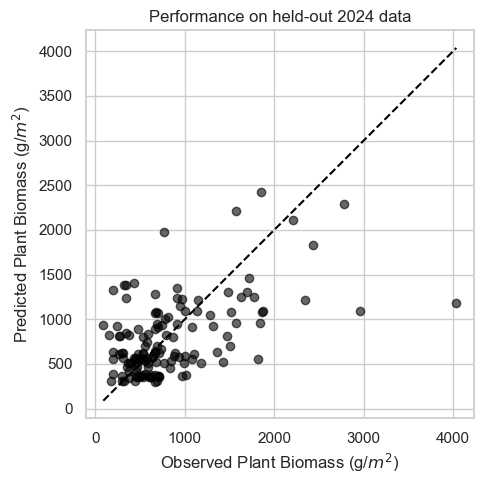

0.25046329031650094
PearsonRResult(statistic=0.5336326556750249, pvalue=2.242667134079666e-11)
528.2390477792493


In [111]:
##USING PEAK INSTEAD OF YEAR - THIS FITS BETTER!!!

plt.figure(figsize=(5, 5))
plt.scatter(peak_val, pred_valpeak, alpha=0.6, color = 'black')
plt.plot(
    [peak_val.min(), peak_val.max()],
    [peak_val.min(), peak_val.max()],
    linestyle='--',
    color = 'black'
)
plt.xlabel('Observed Plant Biomass (g/$m^2$)')
plt.ylabel('Predicted Plant Biomass (g/$m^2$)')
plt.title('Performance on held-out 2024 data')
plt.tight_layout()


##Saving and displaying image
import os
output_dir = r'F:\Figures_PaperII'
file_name = 'testing2024.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)

plt.show()

##Metrics
print(r2_score(peak_val, pred_valpeak))
print(pearsonr(peak_val, pred_valpeak))
print(np.sqrt(metrics.mean_squared_error(peak_val, pred_valpeak)))

In [113]:
sites=groups ##Added, from earlier

unique_sites = np.sort(sites.unique())

In [114]:
sites=groups ##Added, from earlier

unique_sites = np.sort(sites.unique())

all_preds = []

for site in unique_sites:

    train_mask = sites != site
    test_mask  = sites == site

    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]
    X_test  = X.loc[test_mask]
    y_test  = y.loc[test_mask]

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
#     y_train_pred_x = pipe.predict(X_train) ##for plotting training data

    tmp = pd.DataFrame({
        'site': site,
        'observed': y_test.values,
        'predicted': y_pred
    })

    all_preds.append(tmp)

pred_df = pd.concat(all_preds, ignore_index=True)

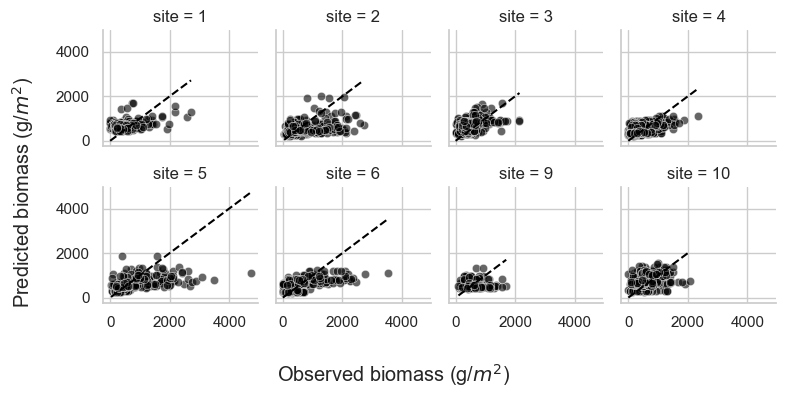

In [115]:
##VALIDATION plotting
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)


import seaborn as sns

target_sites = [1, 2, 3, 4, 5, 6, 9, 10]
plot_df = pred_df[pred_df['site'].isin(target_sites)]
# plot_df = pred_df

g = sns.FacetGrid(plot_df, col="site", col_wrap=4, height=2, sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, x="observed", y="predicted", alpha=0.6, color = 'black')
g.map_dataframe(
    lambda data, **kws: plt.plot(
        [data.observed.min(), data.observed.max()],
        [data.observed.min(), data.observed.max()],
        linestyle='--',
        color = 'black'
    )
)

# g.set_axis_labels("Observed biomass (g/$m^2$)", "Predicted biomass (g/$m^2$)")


# Remove per-axis labels
g.set_axis_labels("", "")

# Add shared labels
g.figure.supxlabel("Observed biomass (g/$m^2$)")
g.figure.supylabel("Predicted biomass (g/$m^2$)")

g.tight_layout()

##Saving and displaying image
import os
output_dir = r'F:\Figures_PaperII'
file_name = 'validation_allsites.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.show()


C:\Users\arj26323\AppData\Local\Temp\ipykernel_18136\3647293968.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_results_x['Cat'] = np.where(all_results_x['Type'] == 'Testing', 'Validation', all_results_x['Type'])


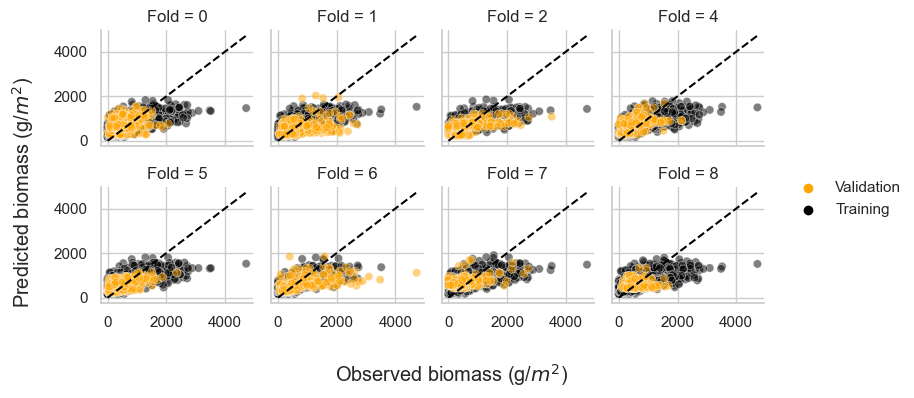

In [117]:
##FOLD plotting

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

target_sites = [1, 2, 3, 4, 5, 6, 9, 10]
all_results_x = all_results[all_results['Site'].isin(target_sites)]
all_results_x['Cat'] = np.where(all_results_x['Type'] == 'Testing', 'Validation', all_results_x['Type'])
# all_results_x = all_results

all_training = all_results_x[all_results_x['Type'] == 'Training']
all_testing = all_results_x[all_results_x['Type'] == 'Testing']

all_results_x = all_results_x.sort_values('Cat')

my_colors = ["orange", "black"]
cat_order = ['Validation', 'Training']

g = sns.FacetGrid(all_results_x, col="Fold", col_wrap=4, height=2, sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, 
                x="Observed", 
                y="Predicted",
                hue = 'Cat', 
#                 style = 'Cat',
                hue_order=cat_order,
                alpha=0.5, 
                palette=my_colors
               )

# g = sns.FacetGrid(all_training, col="Site", col_wrap=4, height=2, sharex=True, sharey=True)
# g.map_dataframe(sns.scatterplot, x="Observed", y="Predicted", alpha=0.6, size = 1, color = 'black', palette=my_colors)
g.map_dataframe(
    lambda data, **kws: plt.plot(
        [data.Observed.min(), data.Observed.max()],
        [data.Observed.min(), data.Observed.max()],
        linestyle='--',
        color = 'black'
    )
)

# g.set_axis_labels("Observed biomass (g/$m^2$)", "Predicted biomass (g/$m^2$)")


# Remove per-axis labels
g.set_axis_labels("", "")

g.add_legend()

# Add shared labels
g.figure.supxlabel("Observed biomass (g/$m^2$)")
g.figure.supylabel("Predicted biomass (g/$m^2$)")

g.tight_layout()

##Saving and displaying image
import os
output_dir = r'F:\Figures_PaperII'
file_name = 'training_testing_final_FOLD_notsite.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)
plt.show()

##Note: the overlap in 'Observed' values is because this is not by fold, it is by site. The training/testing loop ensures that
##there are no overlaps in training/testing values among folds. The site value was assigned as training in one fold
##and validation in another.

In [118]:
all_results_x

# ccc

,Observed,Predicted,Site,Plot,Zone,Year,Species,Type,Fold,Cat
428,345.072,653.637803,9,1.0,3.0,2013,A3,Training,0,Training
13990,192.240,505.988859,2,8.0,2.0,2004,A1,Training,5,Training
13991,253.536,597.961986,2,8.0,2.0,2005,A1,Training,5,Training
13992,360.848,465.261534,2,8.0,2.0,2006,A1,Training,5,Training
13993,275.296,524.347205,2,7.0,2.0,2007,A1,Training,5,Training
...,...,...,...,...,...,...,...,...,...,...
14491,956.656,698.637949,4,7.0,1.0,2000,A1,Testing,5,Validation
14490,501.156,697.529520,4,6.0,1.0,2019,A1,Testing,5,Validation
14489,1076.540,890.854163,4,6.0,1.0,2018,A1,Testing,5,Validation
14495,688.312,896.432785,4,7.0,1.0,2007,A1,Testing,5,Validation


SPATIALLY AGGREGATED METRICS (GROUPED BY SITE)
Mean Grouped Validation RMSE:	230.59
Mean Grouped Validation R^2:	-0.55
----------------------------------------
Mean Grouped Training RMSE:	136.38
Mean Grouped Training R^2:	0.60


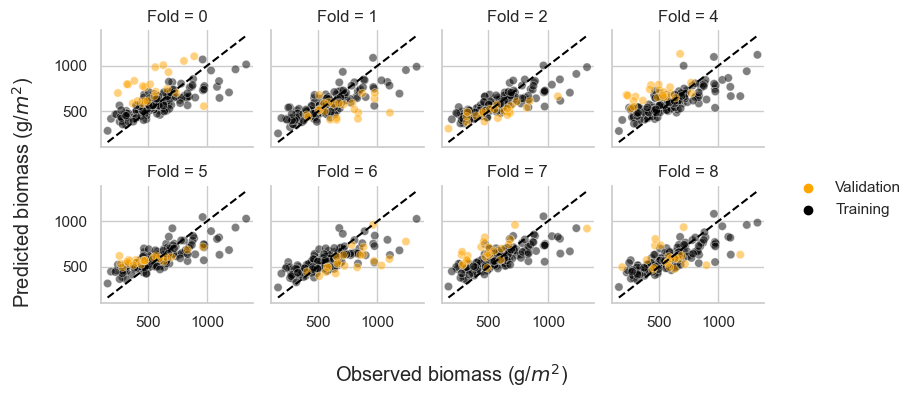

In [119]:
# AGGREGATING TRAINING AND TESTING BY SITE

all_results_x

# 1. Ensure your aggregation includes 'Fold' so you can separate by fold!
# (Notice we add 'Fold' into the groupby keys below)
ccc = all_results_x.groupby(['Fold', 'Year', 'Site', 'Cat', 'Type'], as_index=False).aggregate(
    {
        'Observed': [np.mean], 
        'Predicted': [np.mean]
    }
)

# Flatten multi-index columns if any
ccc.columns = [
    f"{col[0]}" if col[1] else col[0] 
    for col in ccc.columns
]



# 2. Loop through each fold to calculate metrics on the grouped data
grouped_val_rmses = []
grouped_val_maes = []
grouped_val_r2s = []

grouped_train_rmses = []
grouped_train_maes = []
grouped_train_r2s = []

for fold, fold_df in ccc.groupby('Fold'):
    # Separate Training and Testing (Validation) for this fold
    train_fold = fold_df[fold_df['Cat'] == 'Training']
    val_fold = fold_df[fold_df['Cat'] == 'Validation']
    
    # --- Validation / Testing Metrics ---
    if not val_fold.empty:
        v_obs = val_fold['Observed']
        v_pred = val_fold['Predicted']
        
        val_rmse = np.sqrt(mean_squared_error(v_obs, v_pred))
#         val_mae = mean_absolute_error(v_obs, v_pred)
        val_r2 = r2_score(v_obs, v_pred)
        
        grouped_val_rmses.append(val_rmse)
#         grouped_val_maes.append(val_mae)
        grouped_val_r2s.append(val_r2)
        
    # --- Training Metrics ---
    if not train_fold.empty:
        t_obs = train_fold['Observed']
        t_pred = train_fold['Predicted']
        
        train_rmse = np.sqrt(mean_squared_error(t_obs, t_pred))
#         train_mae = mean_absolute_error(t_obs, t_pred)
        train_r2 = r2_score(t_obs, t_pred)
        
        grouped_train_rmses.append(train_rmse)
#         grouped_train_maes.append(train_mae)
        grouped_train_r2s.append(train_r2)

# 3. Print out the spatially aggregated average metrics
print('='*40)
print('SPATIALLY AGGREGATED METRICS (GROUPED BY SITE)')
print('='*40)
print(f"Mean Grouped Validation RMSE:\t{np.mean(grouped_val_rmses):.2f}")
# print(f"Mean Grouped Validation MAE:\t{np.mean(grouped_val_maes):.2f}")
print(f"Mean Grouped Validation R^2:\t{np.mean(grouped_val_r2s):.2f}")
print('-'*40)
print(f"Mean Grouped Training RMSE:\t{np.mean(grouped_train_rmses):.2f}")
# print(f"Mean Grouped Training MAE:\t{np.mean(grouped_train_maes):.2f}")
print(f"Mean Grouped Training R^2:\t{np.mean(grouped_train_r2s):.2f}")




import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)


all_training = ccc[ccc['Type'] == 'Training']
all_testing = ccc[ccc['Type'] == 'Testing']

ccc = ccc.sort_values('Cat')

my_colors = ["orange", "black"]
cat_order = ['Validation', 'Training']

g = sns.FacetGrid(ccc, col="Fold", col_wrap=4, height=2, sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, 
                x="Observed", 
                y="Predicted",
                hue = 'Cat', 
#                 style = 'Cat',
                hue_order=cat_order,
                alpha=0.5, 
                palette=my_colors
               )

# g = sns.FacetGrid(all_training, col="Site", col_wrap=4, height=2, sharex=True, sharey=True)
# g.map_dataframe(sns.scatterplot, x="Observed", y="Predicted", alpha=0.6, size = 1, color = 'black', palette=my_colors)
g.map_dataframe(
    lambda data, **kws: plt.plot(
        [data.Observed.min(), data.Observed.max()],
        [data.Observed.min(), data.Observed.max()],
        linestyle='--',
        color = 'black'
    )
)

g.set_axis_labels("Observed biomass (g/$m^2$)", "Predicted biomass (g/$m^2$)")


# Remove per-axis labels
g.set_axis_labels("", "")

g.add_legend()

# Add shared labels
g.figure.supxlabel("Observed biomass (g/$m^2$)")
g.figure.supylabel("Predicted biomass (g/$m^2$)")

g.tight_layout()

##Saving and displaying image
import os
output_dir = r'F:\Loose figures'
file_name = 'training_testing_FOLD_BY_FOLD.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)
plt.show()

In [120]:
# from sklearn.metrics import (
#     mean_squared_error,
#     mean_absolute_error,
#     r2_score
# )
# import numpy as np
# import pandas as pd

# # Use the spatially aggregated observations already in ccc.
# # IMPORTANT: only evaluate out-of-fold validation predictions here.
# val_all = ccc[ccc['Cat'] == 'Validation'].copy()

# # 1. Overall pooled validation performance
# y_obs = val_all['Observed']
# y_pred = val_all['Predicted']

# pooled_metrics = {
#     'N_site_years': len(val_all),
#     'RMSE': np.sqrt(mean_squared_error(y_obs, y_pred)),
#     'MAE': mean_absolute_error(y_obs, y_pred),
#     'R2': r2_score(y_obs, y_pred)
# }

# print("Pooled validation performance")
# print(pd.Series(pooled_metrics).round(3))


# # 2. Performance at each held-out site
# site_metrics = (
#     val_all.groupby('Site')
#     .apply(
#         lambda d: pd.Series({
#             'N_years': len(d),
#             'Observed_SD': d['Observed'].std(),
#             'RMSE': np.sqrt(mean_squared_error(
#                 d['Observed'], d['Predicted']
#             )),
#             'MAE': mean_absolute_error(
#                 d['Observed'], d['Predicted']
#             ),
#             'R2': (
#                 r2_score(d['Observed'], d['Predicted'])
#                 if len(d) >= 2
#                 and d['Observed'].nunique() >= 2
#                 else np.nan
#             )
#         }),
#     )
#     .reset_index()
# )

# print("\nValidation performance by site")
# print(site_metrics.round(3).to_string(index=False))


# # 3. Typical performance across sites
# print("\nDistribution of site-level errors")
# print(
#     site_metrics[['RMSE', 'MAE', 'R2']]
#     .agg(['median', 'mean', 'min', 'max'])
#     .round(3)
# )

Pooled validation performance
N_site_years    173.000
RMSE            234.498
MAE             191.362
R2               -0.178
dtype: float64

Validation performance by site
 Site  N_years  Observed_SD    RMSE     MAE     R2
    1     22.0      231.167 240.787 212.221 -0.137
    2     22.0      189.071 237.225 180.648 -0.649
    3     22.0      165.262 264.967 230.830 -1.693
    4     22.0      184.682 170.491 147.315  0.107
    5     21.0      209.809 253.009 198.588 -0.527
    6     22.0      209.195 164.554 133.330  0.352
    9     20.0      201.264 217.578 161.877 -0.230
   10     22.0      185.925 296.091 263.736 -1.657

Distribution of site-level errors
           RMSE      MAE     R2
median  239.006  189.618 -0.379
mean    230.588  191.068 -0.554
min     164.554  133.330 -1.693
max     296.091  263.736  0.352


PER-FOLD SPATIALLY AGGREGATED METRICS TABLE
 Fold   Val_RMSE  Val_pearsonR2    Val_R2  Train_RMSE  Train_pearsonR2  Train_R2
    0 296.090788       0.112737 -1.656905  135.653407         0.673509  0.620691
    1 237.224679       0.075431 -0.649196  126.768167         0.692696  0.654660
    2 164.554476       0.668121  0.351783  140.804270         0.652441  0.581759
    4 264.967420       0.271543 -1.693047  140.855312         0.626756  0.586801
    5 170.491211       0.630842  0.107189  141.011442         0.630673  0.579909
    6 253.009415       0.380730 -0.526912  135.838374         0.597822  0.555173
    7 240.787062       0.467428 -0.136627  139.206564         0.621517  0.570232
    8 217.577778       0.011718 -0.230190  130.929674         0.691198  0.640742
Mean Validation RMSE across folds: 230.59
Mean Training RMSE across folds:   136.38
POOLED: 
GLOBAL (POOLED) VALIDATION METRICS
Pooled RMSE:		234.50
Pooled Standard R^2:	-0.18
Pooled Pearson r^2:	0.05


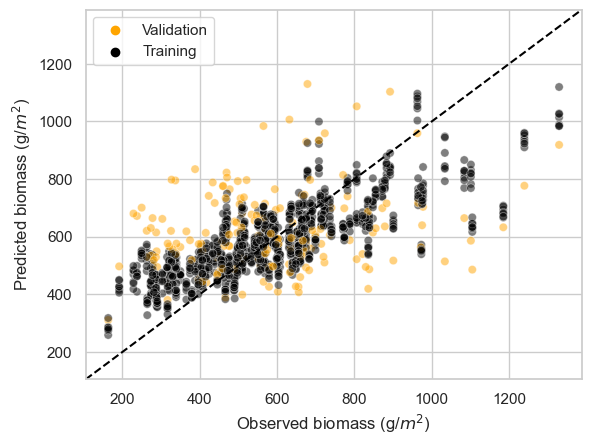

In [121]:
##NOTE: replace 'CCC' woth 'all_results_x' to get informative general breakdown of original plot-level model after step 2

# 1. Group the results while keeping 'Fold', 'Year', 'Site', 'Cat', and 'Type'
ccc = all_results_x.groupby(['Fold', 'Year', 'Site', 'Cat', 'Type'], as_index=False).aggregate(
    {
        'Observed': [np.mean], 
        'Predicted': [np.mean]
    }
)

# Flatten multi-index columns
ccc.columns = [
    f"{col[0]}" if col[1] else col[0] 
    for col in ccc.columns
]

# ccc = all_results_x

# 2. Loop through each fold and store metrics in a list for a table
fold_metrics_list = []

for fold, fold_df in ccc.groupby('Fold'):
    # Separate Training and Testing (Validation) for this fold
    train_fold = fold_df[fold_df['Type'] == 'Training']
    val_fold = fold_df[fold_df['Type'] == 'Testing']
    
    # Dictionary to hold this fold's row data
    row = {'Fold': fold}
    
    # --- Validation / Testing Metrics ---
    if not val_fold.empty:
        v_obs = val_fold['Observed']
        v_pred = val_fold['Predicted']
        
        row['Val_RMSE'] = np.sqrt(mean_squared_error(v_obs, v_pred))
        
        r_pears, _ = pearsonr(v_obs, v_pred)
        row['Val_pearsonR2'] = r_pears ** 2
        row['Val_R2'] = r2_score(v_obs, v_pred)

    else:
        row['Val_RMSE'], row['Val_peasonR2'], row['Val_R2'] = np.nan, np.nan, np.nan
        
    # --- Training Metrics ---
    if not train_fold.empty:
        t_obs = train_fold['Observed']
        t_pred = train_fold['Predicted']
        
        row['Train_RMSE'] = np.sqrt(mean_squared_error(t_obs, t_pred))
        
        r_pears, _ = pearsonr(t_obs, t_pred)
        row['Train_pearsonR2'] = r_pears ** 2
        row['Train_R2'] = r2_score(t_obs, t_pred)
    else:
        row['Train_RMSE'], row['Val_peasonR2'], row['Train_R2'] = np.nan, np.nan, np.nan
        
    fold_metrics_list.append(row)

# 3. Create the summary DataFrame table
metrics_df = pd.DataFrame(fold_metrics_list)

# Set display options to see all columns clearly if desired
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("="*60)
print("PER-FOLD SPATIALLY AGGREGATED METRICS TABLE")
print("="*60)
print(metrics_df.to_string(index=False))

# Optional: Print mean summary below the table
print("="*60)
print(f"Mean Validation RMSE across folds: {metrics_df['Val_RMSE'].mean():.2f}")
print(f"Mean Training RMSE across folds:   {metrics_df['Train_RMSE'].mean():.2f}")
print("="*60)




##POOLED R2 SCORES:
print("POOLED: ")

# Filter for all testing (validation) rows across all folds
val_all = ccc[ccc['Cat'] == 'Validation']

# Optional: If you want it on your spatially grouped data (ccc)
# val_all = ccc[ccc['Type'] == 'Testing']

v_obs = val_all['Observed']
v_pred = val_all['Predicted']

global_rmse = np.sqrt(mean_squared_error(v_obs, v_pred))
global_r2 = r2_score(v_obs, v_pred)
global_pearson, _ = pearsonr(v_obs, v_pred)

print("="*40)
print("GLOBAL (POOLED) VALIDATION METRICS")
print("="*40)
print(f"Pooled RMSE:\t\t{global_rmse:.2f}")
print(f"Pooled Standard R^2:\t{global_r2:.2f}")
print(f"Pooled Pearson r^2:\t{global_pearson**2:.2f}")

val_all
##SINGLE SCATTERPLOT:
g = sns.scatterplot(
    data=ccc,
    x="Observed",
    y="Predicted",
    hue="Cat",
    hue_order=cat_order,
    alpha=0.5,
    palette=my_colors
)

lims = [
    min(g.get_xlim()[0], g.get_ylim()[0]),
    max(g.get_xlim()[1], g.get_ylim()[1])
]

g.plot(lims, lims, linestyle="--", color="black")
g.set_xlim(lims)
g.set_ylim(lims)
g.set_xlabel("Observed biomass (g/$m^2$)")
g.set_ylabel("Predicted biomass (g/$m^2$)")

# Remove legend title
g.legend_.set_title(None)

C:\Users\arj26323\AppData\Local\Temp\ipykernel_18136\352451017.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_results_x['Cat'] = np.where(all_results_x['Type'] == 'Testing', 'Validation', all_results_x['Type'])


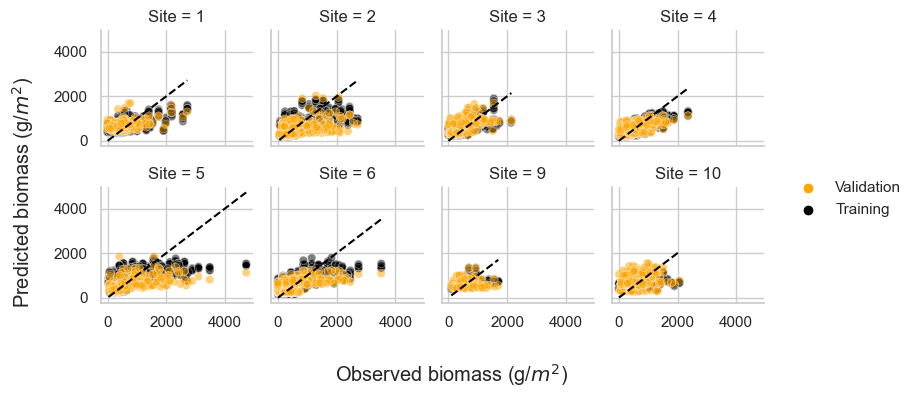

In [122]:
##SITE plotting

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

target_sites = [1, 2, 3, 4, 5, 6, 9, 10]
all_results_x = all_results[all_results['Site'].isin(target_sites)]
all_results_x['Cat'] = np.where(all_results_x['Type'] == 'Testing', 'Validation', all_results_x['Type'])
# all_results_x = all_results

all_training = all_results_x[all_results_x['Type'] == 'Training']
all_testing = all_results_x[all_results_x['Type'] == 'Testing']

all_results_x = all_results_x.sort_values('Cat')

my_colors = ["orange", "black"]
cat_order = ['Validation', 'Training']

g = sns.FacetGrid(all_results_x, col="Site", col_wrap=4, height=2, sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, 
                x="Observed", 
                y="Predicted",
                hue = 'Cat', 
#                 style = 'Cat',
                hue_order=cat_order,
                alpha=0.5, 
                palette=my_colors
               )

# g = sns.FacetGrid(all_training, col="Site", col_wrap=4, height=2, sharex=True, sharey=True)
# g.map_dataframe(sns.scatterplot, x="Observed", y="Predicted", alpha=0.6, size = 1, color = 'black', palette=my_colors)
g.map_dataframe(
    lambda data, **kws: plt.plot(
        [data.Observed.min(), data.Observed.max()],
        [data.Observed.min(), data.Observed.max()],
        linestyle='--',
        color = 'black'
    )
)

# g.set_axis_labels("Observed biomass (g/$m^2$)", "Predicted biomass (g/$m^2$)")


# Remove per-axis labels
g.set_axis_labels("", "")

g.add_legend()

# Add shared labels
g.figure.supxlabel("Observed biomass (g/$m^2$)")
g.figure.supylabel("Predicted biomass (g/$m^2$)")

g.tight_layout()

##Saving and displaying image
import os
output_dir = r'F:\Figures_PaperII'
file_name = 'training_testing_final.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)
plt.show()

##Note: the overlap in 'Observed' values is because this is not by fold, it is by site. The training/testing loop ensures that
##there are no overlaps in training/testing values among folds. The site value was assigned as training in one fold
##and validation in another.

In [123]:
all_training[all_training['Site'] == 1]

all_testing[all_testing['Site'] == 1]

df_tx = pd.concat([all_training, all_testing])

duplicates = (
    df_tx.groupby(["Site", "Observed"])["Cat"]
      .nunique()
      .reset_index()
      .query("Cat > 1")
)

print(duplicates)

df_tx

leakage = df_tx.merge(
    duplicates[["Site", "Observed"]],
    on=["Site", "Observed"],
    how="inner"
).sort_values(["Site", "Observed"])

print(leakage)


all_testing

      Site  Observed  Cat
0        1     0.000    2
1        1     4.348    2
2        1    20.840    2
3        1    29.144    2
4        1    34.464    2
...    ...       ...  ...
2468    10  1517.088    2
2469    10  1658.128    2
2470    10  1803.776    2
2471    10  1890.688    2
2472    10  2061.584    2

[2473 rows x 3 columns]
       Observed   Predicted  Site  Plot  Zone  Year Species      Type  Fold         Cat
14824     0.000  631.885076     1   1.0   1.0  2017      A1  Training     0    Training
14825     0.000  474.176580     1   4.0   1.0  2016      A1  Training     0    Training
14826     0.000  477.869199     1   5.0   1.0  2016      A1  Training     0    Training
14827     0.000  632.926583     1   4.0   1.0  2017      A1  Training     0    Training
14828     0.000  616.225909     1   5.0   1.0  2017      A1  Training     0    Training
...         ...         ...   ...   ...   ...   ...     ...       ...   ...         ...
19275  2061.584  643.812637    10   6.0   2.0  

,Observed,Predicted,Site,Plot,Zone,Year,Species,Type,Fold,Cat
2543,617.936,791.795205,10,1.0,1.0,2000,A1,Testing,0,Validation
2544,559.828,867.933601,10,1.0,1.0,2001,A1,Testing,0,Validation
2545,390.444,850.600038,10,1.0,1.0,2004,A1,Testing,0,Validation
2546,1310.576,1130.193425,10,1.0,1.0,2005,A1,Testing,0,Validation
2547,928.708,898.771191,10,1.0,1.0,2007,A1,Testing,0,Validation
...,...,...,...,...,...,...,...,...,...,...
23499,863.856,488.829331,9,8.0,3.0,2018,A3,Testing,8,Validation
23500,652.608,455.125362,9,8.0,3.0,2019,A3,Testing,8,Validation
23501,609.200,545.666848,9,8.0,3.0,2021,A3,Testing,8,Validation
23502,1123.984,480.306932,9,7.0,3.0,2022,A3,Testing,8,Validation


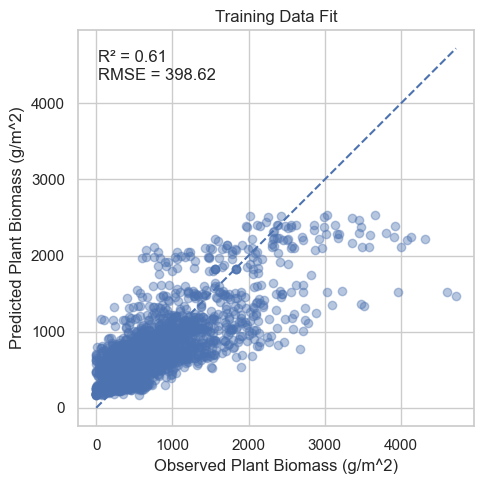

In [124]:
y_train_pred = pipe.predict(X_train)

from sklearn.metrics import r2_score, mean_squared_error

r2 = r2_score(y_train, y_train_pred)
rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

plt.figure(figsize=(5, 5))
plt.scatter(y_train, y_train_pred, alpha=0.4)
plt.plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)

plt.text(
    0.05, 0.95,
    f'R² = {r2:.2f}\nRMSE = {rmse:.2f}',
    transform=plt.gca().transAxes,
    verticalalignment='top'
)

plt.xlabel('Observed Plant Biomass (g/m^2)')
plt.ylabel('Predicted Plant Biomass (g/m^2)')
plt.title('Training Data Fit')
plt.tight_layout()
plt.show()

In [125]:
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

to_drop = [c for c in upper.columns if any(upper[c] > 0.9)]
X_reduced = X.drop(columns=to_drop)


X_reduced

corr

,evi_max_05_10,slope,elevation,Percent_flooding,srad_peak,dayl_Max,nd_swir2_nir_mean_05_10,ndvi_mean_08_10,nd_r_g_max_05_10,spei14d
evi_max_05_10,1.000000,0.108865,0.003358,0.494893,0.069953,0.496944,0.442244,0.878324,0.101249,0.211545
slope,0.108865,1.000000,0.417086,0.059910,0.017945,0.025586,0.257998,0.106502,0.180583,0.002191
elevation,0.003358,0.417086,1.000000,0.201632,0.083543,0.018931,0.253585,0.012640,0.136507,0.037102
Percent_flooding,0.494893,0.059910,0.201632,1.000000,0.050670,0.129932,0.089756,0.530736,0.168746,0.080675
srad_peak,0.069953,0.017945,0.083543,0.050670,1.000000,0.046124,0.038138,0.073649,0.049581,0.236008
dayl_Max,0.496944,0.025586,0.018931,0.129932,0.046124,1.000000,0.212951,0.390675,0.141048,0.047142
nd_swir2_nir_mean_05_10,0.442244,0.257998,0.253585,0.089756,0.038138,0.212951,1.000000,0.444119,0.226229,0.048307
ndvi_mean_08_10,0.878324,0.106502,0.012640,0.530736,0.073649,0.390675,0.444119,1.000000,0.046809,0.209794
nd_r_g_max_05_10,0.101249,0.180583,0.136507,0.168746,0.049581,0.141048,0.226229,0.046809,1.000000,0.000926
spei14d,0.211545,0.002191,0.037102,0.080675,0.236008,0.047142,0.048307,0.209794,0.000926,1.000000


In [42]:
print(len(yargs))

##More work to do
# feature_importance_df

# ##Export csv dataframe
# out_dir = os.path.expanduser('C:/Users/arj26323/Documents/Data/Biomass datasets/Combined_GA_VA')
# out_csv = os.path.join(out_dir, 'ga_2025.csv')
# df0.to_csv(out_csv, index = False)

2938


In [43]:
# g = df0.plot(kind = 'scatter', x = 'Percent_flooding', y = 'Plant_Biomass')
# g = df0.plot(kind = 'scatter', x = 'nd_swir2_nir_mean_01_12', y = 'Plant_Biomass')
# g = df0.plot(kind = 'scatter', x = 'flats_min_03_05', y = 'Plant_Biomass')
# g = df0.plot(kind = 'scatter', x = 'elevation', y = 'Plant_Biomass')
# g = df0.plot(kind = 'scatter', x = 'evi_max_05_10', y = 'Plant_Biomass')

# g

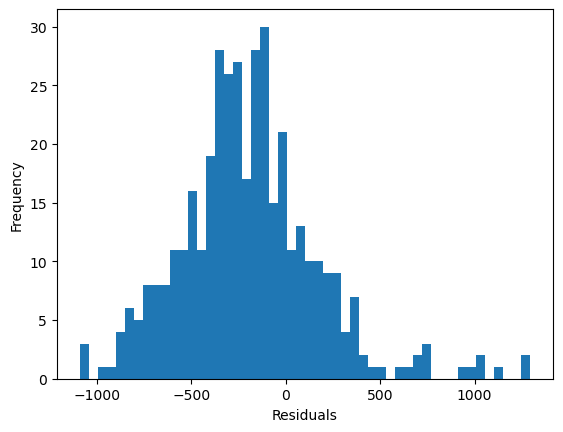

In [44]:
import matplotlib.pyplot as plt
residuals = y_test - y_pred
plt.hist(residuals, bins=50)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

# plt.scatter(yargs_test, y_pred)
# plt.xlabel("Actual Biomass")
# plt.ylabel("Predicted Biomass")
# plt.plot([min(yargs_test), max(yargs_test)], [min(yargs_test), max(yargs_test)], 'r--')
# plt.show()

In [45]:
import os
# os.chdir('C:\\Users\\arj26323\\Documents\\Data')
# os.getcwd()

# from joblib import dump

# # Save the whole pipeline (including preprocessing and model)
# dump(pipe, 'rf_pipeline.joblib')

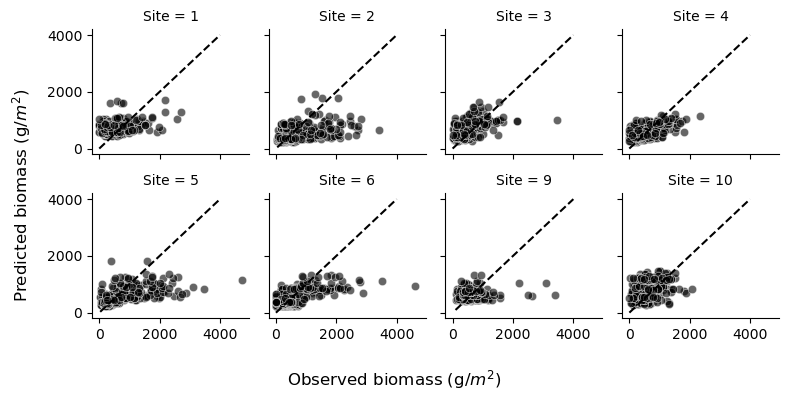

In [46]:
##GEE Java output comparison

dfdf = pd.read_csv('F:/Figures_PaperII/GEE_valdata/LOSO_Predictions_Export.csv')

target_sites = [1, 2, 3, 4, 5, 6, 9, 10]
plot_dfdf = dfdf[dfdf['Site'].isin(target_sites)]
# plot_dfdf = dfdf

g = sns.FacetGrid(plot_dfdf, col="Site", col_wrap=4, height=2, sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, x="Plant_Biomass", y="prediction", alpha=0.6, color = 'black')

# g.map_dataframe(
#     lambda data, **kws: plt.plot(
#         [data.Plant_Biomass.min(), data.Plant_Biomass.max()],
#         [data.Plant_Biomass.min(), data.Plant_Biomass.max()],
#         linestyle='--',
#         color = 'black'
#     )
# )

##Changing max values
g.map_dataframe(
    lambda data, **kws: plt.plot(
        [data.Plant_Biomass.min(), 4000],
        [data.Plant_Biomass.min(), 4000],
        linestyle='--',
        color = 'black'
    )
)


# g.set_axis_labels("Observed biomass (g/$m^2$)", "Predicted biomass (g/$m^2$)")


# Remove per-axis labels
g.set_axis_labels("", "")

# Add shared labels
g.figure.supxlabel("Observed biomass (g/$m^2$)")
g.figure.supylabel("Predicted biomass (g/$m^2$)")

g.tight_layout()

##Saving and displaying image
import os
output_dir = r'F:\Figures_PaperII'
file_name = 'validation_allsites_new.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.show()


##ALMOST EXACTLY THE SAME!! GEE and PYTHON GETTING ALONG! GREAT NEWS!

In [126]:
len(all_results_x[all_results_x['Type'] == 'Training'])

# 136/(251+2259+136)

# peak_val

17570/7

2510.0

In [127]:
all_results_x

dfz = all_results_x ##multiple (7) ttraining predicted values for single observed predicted value

dfz['Observed'].nunique()

# dfz

2444

In [135]:
# df = dfz.copy() ##BE VERY CAREFUL

# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# import seaborn as sns

# # Assuming your dataframe has columns:
# # ['Observed', 'Predicted', 'Site', 'Plot', 'Year', 'Cat']

# # 1. Aggregate Training predictions per INDIVIDUAL PLOT across the 7 folds
# train_df = df[df["Cat"] == "Training"]
# train_agg = (
#     train_df.groupby(["Site", "Plot", "Year"])
#     .agg(
#         Observed=(
#             "Observed",
#             "first",
#         ),  # Observed value for this specific plot/year
#         Pred_Train_Mean=("Predicted", "mean"),
#         Pred_Train_Std=("Predicted", "std"),
#     )
#     .reset_index()
# )

# # Calculate confidence bounds for training predictions
# train_agg["Train_Upper"] = (
#     train_agg["Pred_Train_Mean"] + train_agg["Pred_Train_Std"]
# )
# train_agg["Train_Lower"] = (
#     train_agg["Pred_Train_Mean"] - train_agg["Pred_Train_Std"]
# )

# # 2. Isolate Validation predictions per INDIVIDUAL PLOT
# # (Note: In your LOSO setup, a validation prediction is the single held-out prediction for that plot/year)
# val_df = df[df["Cat"] == "Validation"][
#     ["Site", "Plot", "Year", "Observed", "Predicted"]
# ].rename(columns={"Predicted": "Pred_Val"})

# # Merge training and validation data together at the Plot-Year level
# merged_df = pd.merge(
#     train_agg,
#     val_df[["Site", "Plot", "Year", "Pred_Val"]],
#     on=["Site", "Plot", "Year"],
#     how="left",
# )

# merged_df

,Site,Plot,Year,Observed,Pred_Train_Mean,Pred_Train_Std,Train_Upper,Train_Lower,Pred_Val
0,1,1.0,2000,454.160,537.555260,73.291756,610.847016,464.263505,738.201713
1,1,1.0,2000,454.160,537.555260,73.291756,610.847016,464.263505,787.051704
2,1,1.0,2001,300.704,499.763655,57.299842,557.063497,442.463813,585.371501
3,1,1.0,2001,300.704,499.763655,57.299842,557.063497,442.463813,697.246812
4,1,1.0,2002,662.896,622.697487,64.992613,687.690100,557.704873,590.162141
...,...,...,...,...,...,...,...,...,...
2420,10,8.0,2020,1038.256,683.807632,107.013669,790.821301,576.793963,735.123744
2421,10,8.0,2020,1038.256,683.807632,107.013669,790.821301,576.793963,1145.390602
2422,10,8.0,2022,941.664,546.183149,106.308806,652.491956,439.874343,655.683534
2423,10,8.0,2022,941.664,546.183149,106.308806,652.491956,439.874343,715.938731


In [138]:
df = dfz.copy() ##BE VERY CAREFUL

# 1. Aggregate Training across folds AND plots per Site-Year
train_agg = (
    df[df["Cat"] == "Training"]
    .groupby(["Site", "Year"])
    .agg(
        Observed_Mean=("Observed", "mean"),
        Observed_Std=("Observed", "std"),
        Train_Mean=("Predicted", "mean"),
        Train_Std=("Predicted", "std"),
    )
    .reset_index()
)

# 2. Aggregate Validation across plots per Site-Year
val_agg = (
    df[df["Cat"] == "Validation"]
    .groupby(["Site", "Year"])
    .agg(
        Val_Mean=("Predicted", "mean"),
        Val_Std=("Predicted", "std"),
    )
    .reset_index()
)

# 3. Merge them together into a clean site-level time series dataframe
site_ts_df = pd.merge(train_agg, val_agg, on=["Site", "Year"], how="inner")

# Calculate upper/lower bounds for nice confidence ribbons (Mean +/- 1 SD)
for prefix in ["Observed", "Train", "Val"]:
    site_ts_df[f"{prefix}_Upper"] = (
        site_ts_df[f"{prefix}_Mean"] + site_ts_df[f"{prefix}_Std"]
    )
    site_ts_df[f"{prefix}_Lower"] = (
        site_ts_df[f"{prefix}_Mean"] - site_ts_df[f"{prefix}_Std"]
    )
    
site_ts_df

,Site,Year,Observed_Mean,Observed_Std,Train_Mean,Train_Std,Val_Mean,Val_Std,Observed_Upper,Observed_Lower,Train_Upper,Train_Lower,Val_Upper,Val_Lower
0,1,2000,607.538000,235.882155,534.631936,89.739501,699.031229,63.643143,843.420155,371.655845,624.371438,444.892435,762.674372,635.388085
1,1,2001,475.917500,214.057181,476.860923,52.240452,607.352146,47.012667,689.974681,261.860319,529.101375,424.620470,654.364813,560.339480
2,1,2002,508.253714,290.088083,572.902214,57.694158,632.005870,89.341590,798.341798,218.165631,630.596372,515.208056,721.347460,542.664279
3,1,2004,469.346500,236.889177,657.079369,71.289751,822.675270,80.548669,706.235677,232.457323,728.369120,585.789619,903.223939,742.126601
4,1,2005,1329.427000,589.548387,1020.781873,257.706904,918.818364,223.515351,1918.975387,739.878613,1278.488777,763.074969,1142.333715,695.303013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
168,10,2018,973.074000,573.773058,554.750308,88.742595,556.906087,165.186980,1546.847058,399.300942,643.492902,466.007713,722.093066,391.719107
169,10,2019,471.967667,204.534012,491.601480,58.816001,612.703521,152.243010,676.501679,267.433654,550.417481,432.785479,764.946530,460.460511
170,10,2020,740.747333,336.580469,618.878393,90.320935,700.615183,213.208824,1077.327802,404.166864,709.199328,528.557458,913.824007,487.406360
171,10,2021,456.956833,185.727666,513.979411,60.660496,586.212152,157.475493,642.684499,271.229167,574.639907,453.318915,743.687644,428.736659


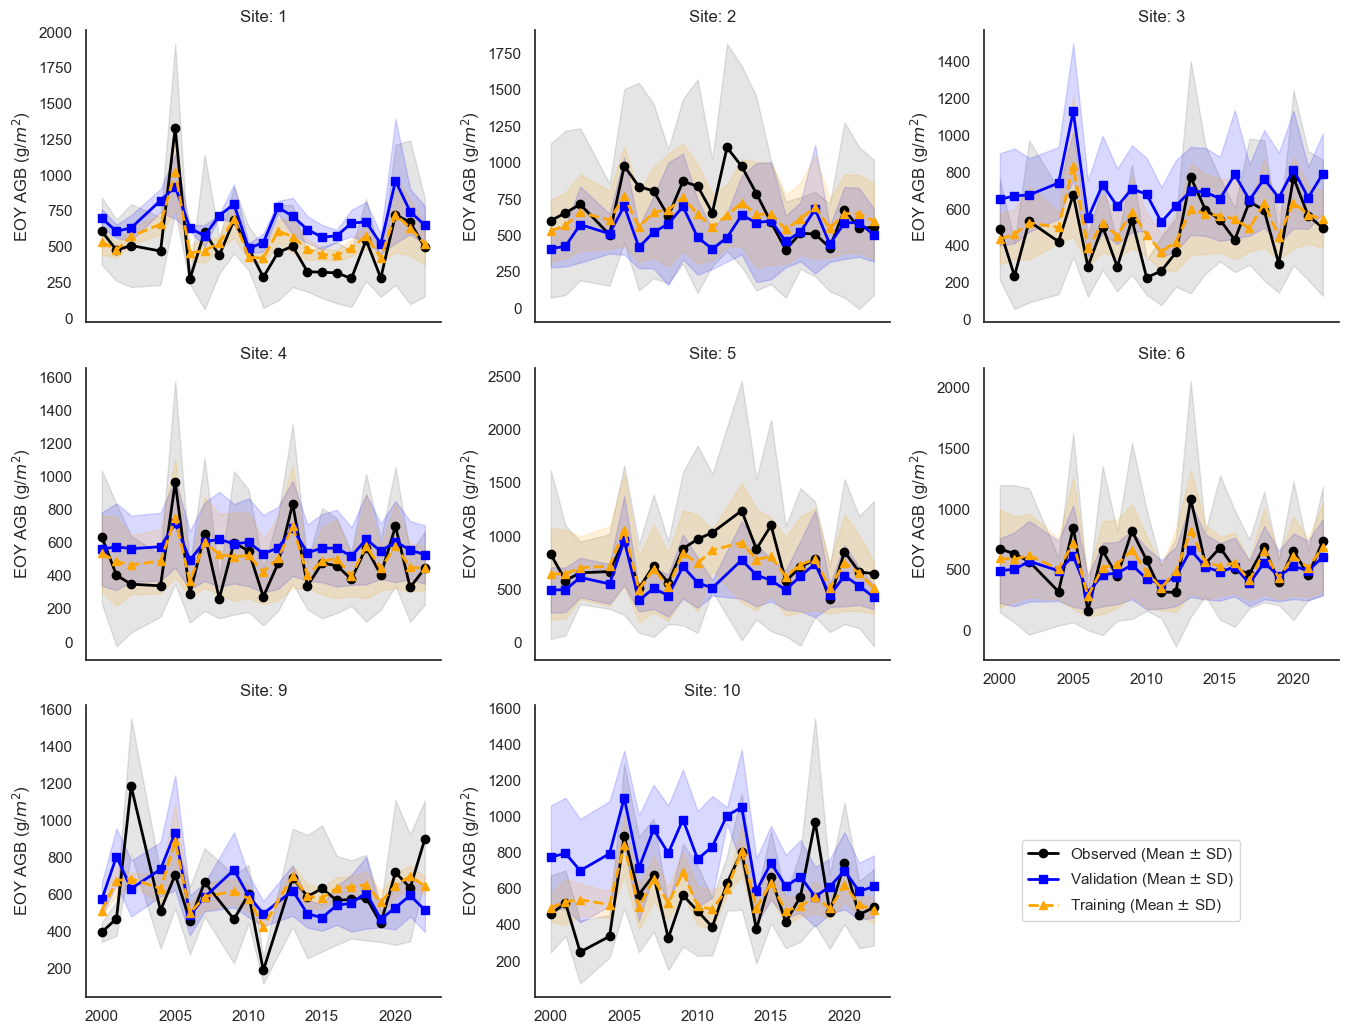

In [162]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")

# Select a subset of sites to visualize
sample_sites = site_ts_df["Site"].unique()[:10]
plot_data = site_ts_df[site_ts_df["Site"].isin(sample_sites)]

g = sns.FacetGrid(
    plot_data,
    col="Site",
    col_wrap=3,
    height=3.5,
    aspect=1.3,
    sharey=False,
)

for site, ax in g.axes_dict.items():
    sub_df = plot_data[plot_data["Site"] == site].sort_values("Year")
    if sub_df.empty:
        continue

    # --- 1. Observed Trend (Black line + Ribbon) ---
    ax.fill_between(
        sub_df["Year"],
        sub_df["Observed_Lower"],
        sub_df["Observed_Upper"],
        color="black",
        alpha=0.1,
    )
    ax.plot(
        sub_df["Year"],
        sub_df["Observed_Mean"],
        color="black",
        marker="o",
        linewidth=2,
        label="Observed (Mean $\pm$ SD)",
    )

    # --- 2. Validation Prediction Trend (Blue line + Ribbon) ---
    ax.fill_between(
        sub_df["Year"],
        sub_df["Val_Lower"],
        sub_df["Val_Upper"],
        color="blue",
        alpha=0.15,
    )
    ax.plot(
        sub_df["Year"],
        sub_df["Val_Mean"],
        color="blue",
        marker="s",
        linestyle="-",
        linewidth=2,
        label="Validation (Mean $\pm$ SD)",
    )

    # --- 3. Training Prediction Trend (Orange dashed line + Ribbon) ---
    ax.fill_between(
        sub_df["Year"],
        sub_df["Train_Lower"],
        sub_df["Train_Upper"],
        color="orange",
        alpha=0.15,
    )
    ax.plot(
        sub_df["Year"],
        sub_df["Train_Mean"],
        color="orange",
        marker="^",
        linestyle="--",
        linewidth=2,
        label="Training (Mean $\pm$ SD)",
    )

    ax.set_title(f"Site: {site}")
    ax.set_xlabel("")
    ax.set_ylabel("EOY AGB (g/$m^2$)")

# Add a unified legend
handles, labels = g.axes[0].get_legend_handles_labels()
g.fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.92, .2))

plt.tight_layout()

##Save at high res
import os
output_dir = r'F:\Loose figures'
file_name = 'pennings_series_correspondence_standardized.tif'

save_path = os.path.join(output_dir, file_name)

# plt.savefig(save_path, bbox_inches='tight', dpi=1000)

plt.show()

In [150]:
# Calculate year-to-year differences for a site's time series
obs_diff = sub_df["Observed_Mean"].diff().dropna()
val_diff = sub_df["Val_Mean"].diff().dropna()
trend_corr, _ = pearsonr(obs_diff, val_diff)

In [151]:

import numpy as np
from scipy.stats import pearsonr


def calculate_kge(observed, predicted):
    """Calculates Kling-Gupta Efficiency"""
    r = pearsonr(observed, predicted)[0]
    alpha = np.std(predicted) / np.std(observed)
    beta = np.mean(predicted) / np.mean(observed)
    return 1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)


trend_metrics = []

for site, group in site_ts_df.groupby("Site"):
    sub = group.sort_values("Year").dropna(
        subset=["Observed_Mean", "Val_Mean"]
    )

    if len(sub) > 3:  # Need enough years to evaluate a trend
        obs = sub["Observed_Mean"].values
        pred = sub["Val_Mean"].values

        # 1. Standard Correlation & KGE on absolute values
        r_val, _ = pearsonr(obs, pred)
        kge_val = calculate_kge(obs, pred)

        # 2. Year-to-year anomaly tracking (First Difference)
        obs_diff = np.diff(obs)
        pred_diff = np.diff(pred)
        if len(obs_diff) > 1 and np.std(obs_diff) > 0 and np.std(pred_diff) > 0:
            diff_corr, _ = pearsonr(obs_diff, pred_diff)
        else:
            diff_corr = np.nan

        trend_metrics.append(
            {
                "Site": site,
                "Pearson_R": r_val,
                "KGE": kge_val,
                "Year_To_Year_Corr": diff_corr,
            }
        )

trend_metrics_df = pd.DataFrame(trend_metrics)
print(trend_metrics_df)

# Print median performance across all your sites
print("\n--- Median Trend Metrics Across Sites ---")
print(trend_metrics_df[["Pearson_R", "KGE", "Year_To_Year_Corr"]].median())

   Site  Pearson_R       KGE  Year_To_Year_Corr
0     1   0.683687  0.341146           0.586012
1     2   0.274647  0.087937           0.529899
2     3   0.521098  0.275612           0.559154
3     4   0.794256  0.226724           0.840976
4     5   0.617033  0.417976           0.767259
5     6   0.817387  0.349552           0.870346
6     9   0.108250  0.022681           0.073535
7    10   0.335763  0.208794           0.686870

--- Median Trend Metrics Across Sites ---
Pearson_R            0.569066
KGE                  0.251168
Year_To_Year_Corr    0.636441
dtype: float64


In [ ]:
'''
*   **Interpretation:** This tells you: *"When the observed biomass unexpectedly drops or spikes in a given year, 
does the model successfully predict that same directional shift?"*

#### 3. Dynamic Time Warping (DTW) Distance
If your predicted peaks or troughs are slightly phase-shifted by a year, standard metrics will heavily penalize them. 
DTW measures the overall "shape" similarity of two time series even if they stretch or compress slightly along the time axis.
*   *(Note: You can implement this easily using Python's `fastdtw` or `dtaidistance` libraries).*

---
'''

In [152]:
# def calculate_nse(observed, predicted):
#     """Calculates Nash-Sutcliffe Efficiency"""
#     return 1 - (np.sum((observed - predicted) ** 2) / np.sum((observed - np.mean(observed)) ** 2))

# def calculate_rmse(observed, predicted):
#     """Calculates Root Mean Squared Error"""
#     return np.sqrt(np.mean((observed - predicted) ** 2))

# # Compute metrics per site for Validation and Training
# metrics_list = []

# for site, group in merged_df.groupby("Site"):
#     # Drop rows with missing values for clean math
#     val_subset = group.dropna(subset=["Observed", "Pred_Val"])
#     train_subset = group.dropna(subset=["Observed", "Pred_Train_Mean"])
    
#     if len(val_subset) > 2:  # Ensure enough points to evaluate
#         metrics_list.append({
#             "Site": site,
#             "Type": "Validation",
#             "RMSE": calculate_rmse(val_subset["Observed"], val_subset["Pred_Val"]),
#             "NSE": calculate_nse(val_subset["Observed"], val_subset["Pred_Val"])
#         })
        
#     if len(train_subset) > 2:
#         metrics_list.append({
#             "Site": site,
#             "Type": "Training",
#             "RMSE": calculate_rmse(train_subset["Observed"], train_subset["Pred_Train_Mean"]),
#             "NSE": calculate_nse(train_subset["Observed"], train_subset["Pred_Train_Mean"])
#         })

# metrics_df = pd.DataFrame(metrics_list)

# # Visualize the distribution of performance across plots using Boxplots
# plt.figure(figsize=(12, 5))

# plt.subplot(1, 2, 1)
# sns.boxplot(data=metrics_df, x="Type", y="RMSE", palette="Set2")
# plt.title("Plot-Level RMSE Distribution")

# plt.subplot(1, 2, 2)
# sns.boxplot(data=metrics_df, x="Type", y="NSE", palette="Set2")
# plt.title("Plot-Level NSE Distribution (Higher is Better)")

# plt.tight_layout()
# plt.show()

# # Print summary stats to inspect overfitting
# print(metrics_df.groupby("Type")[["RMSE", "NSE"]].median())

In [61]:
#Finito